I will be using the load_breast_cancer library from sklearn.datasets to use a simple logistic regression model to do binary classification on whether a patient has breast cancer (melignant) or does not have breast cancer (benign)

In [1]:
from sklearn.datasets import load_breast_cancer
import numpy as np
import pandas as pd
data = load_breast_cancer()
features = data.data
labels = data.target
df = pd.DataFrame(features, columns=data.feature_names)
df['has_cancer'] = labels


We need to change the target column because malignant was labeled as 0 and benign was 1, but our confusion matrix expects 1 to be positive and 0 to be negative

In [2]:
df['target'] = (df['has_cancer']==0).astype(int)
df = df.drop(columns='has_cancer')


In [3]:
#splitting into features and target
X = df.drop('target', axis=1)
y = df['target']

Now we need to seperate the training values from testing values and stratify on the targets so there is same amount of positive values, important for classification

In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

I'm pretty sure this data is pretty clean but I'm going to perform some EDA on it to get a better insight

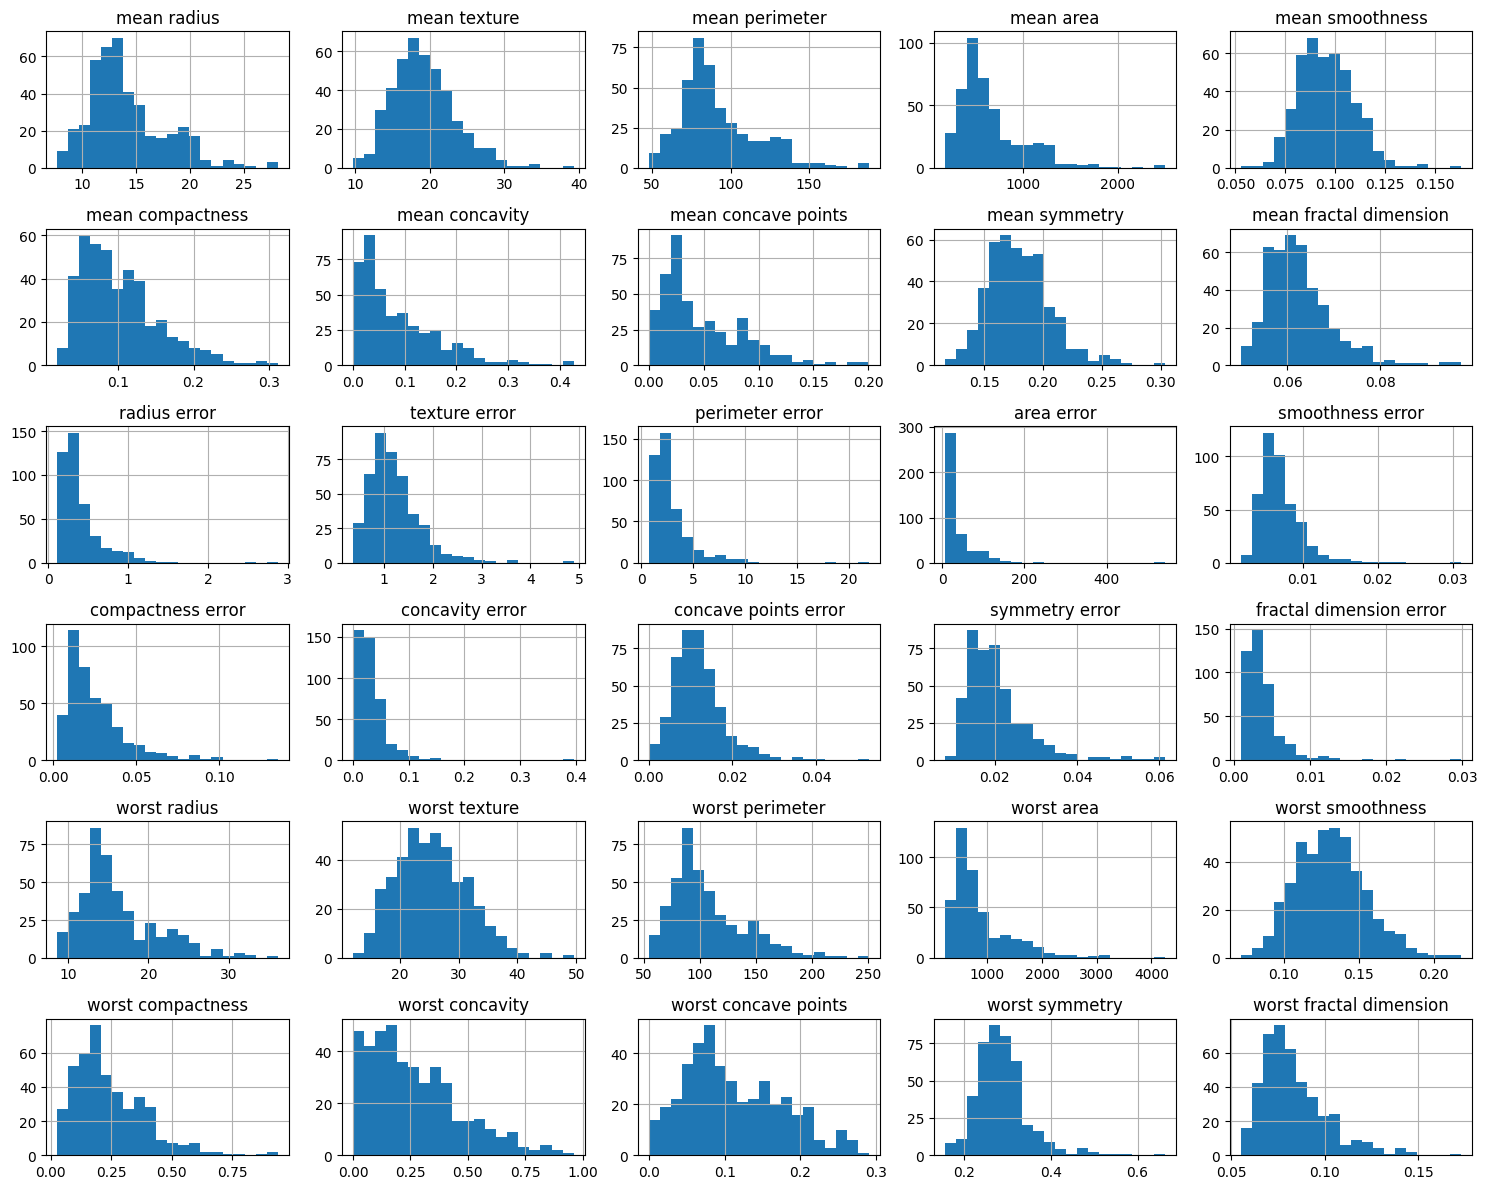

In [5]:
#looking at histograms for all the features
import matplotlib.pyplot as plt
X_train.hist(bins=20, figsize=(15,12))
plt.tight_layout()
plt.show()

From the histograms above I'm going to try to normalize the mean_area, mean_compactness, mean_concavity, mean_concavity_points, radius_error,texture_error,perimiter_error,area_error,smothness_error

In [ ]:
from sklearn.preprocessing import FunctionTransformer
#creating a custom transformer to take the log of the data to normalize
log_transformer = FunctionTransformer(np.log1p)



Lets see it we can find which features are most correlated to the target

In [23]:
training_df = X_train.copy()
training_df['label'] = y_train.copy()
corr_matrix = training_df.corr()
corr_matrix['label'].sort_values(ascending=False)

label                      1.000000
worst concave points       0.786883
mean concave points        0.774572
worst perimeter            0.769581
worst radius               0.762155
mean perimeter             0.726986
worst area                 0.717141
mean radius                0.713696
mean area                  0.690171
mean concavity             0.684101
worst concavity            0.663487
mean compactness           0.583200
worst compactness          0.575841
radius error               0.544692
perimeter error            0.528133
area error                 0.514355
worst texture              0.469603
worst symmetry             0.442691
worst smoothness           0.418416
mean texture               0.417589
concave points error       0.395656
mean smoothness            0.370402
mean symmetry              0.362264
worst fractal dimension    0.290074
compactness error          0.262476
concavity error            0.245150
fractal dimension error    0.051991
symmetry error             0

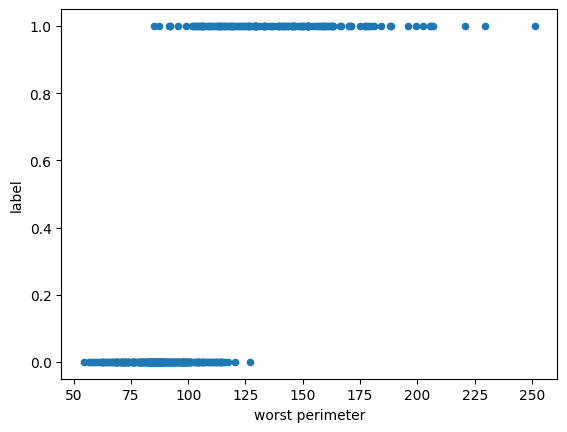

In [26]:
training_df.plot(kind='scatter', x='worst perimeter', y='label')
plt.show()

Now lets create a pipeline to scale the data and then train using logistic regression model and also a pipeline for the log

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
process_skew = Pipeline([
    ('log', log_transformer),
    ('scale', StandardScaler())
])
logged_cols = ['mean area','mean compactness','mean concavity','mean concave points','radius error','texture error','perimeter error','area error','smoothness error']
#all other feature transformations are scaling
remainer_transform = Pipeline([
    ('scale', StandardScaler())
])
processed = ColumnTransformer([
    ('pre_process', process_skew, logged_cols)
], remainder=remainer_transform)

predictor = Pipeline([
    ('pre', processed),
    ('model', LogisticRegression())
])

Now we are going to use the cross validation predict function to get an array of predictions for each fold so that we are not running a prediction on values it trained from. Then, we will use those to plug into our confusion matrix to get a true sense of the accuracy of the model

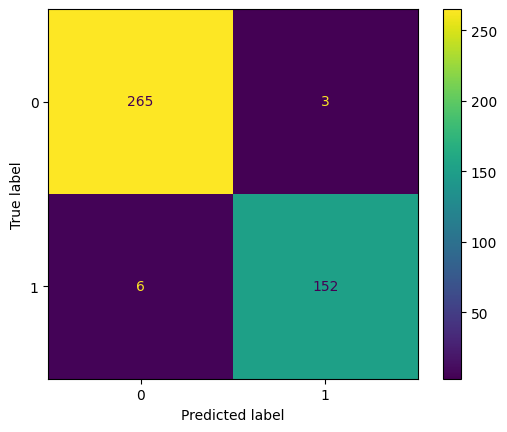

In [12]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
predictions_arr = cross_val_predict(predictor, X_train, y_train, cv=5) #5 folded cv
cm = confusion_matrix(y_true=y_train, y_pred=predictions_arr)
cm_plt = ConfusionMatrixDisplay(cm)
cm_plt.plot()



Using our confusion matrix lets get the accuracy data 

In [18]:
from sklearn.metrics import recall_score, precision_score, f1_score, accuracy_score
recall = recall_score(y_true=y_train, y_pred=predictions_arr) #percentage of positive identified from FN and TP
precision = precision_score(y_true=y_train, y_pred=predictions_arr) #percentage of correct positive from TP and FP
f1 = f1_score(y_true=y_train, y_pred=predictions_arr)
total_accuracy = accuracy_score(y_true=y_train, y_pred=predictions_arr)


In our model we got a 97% F1 score for the confusion matrix which is very good. This shows our model is classifying correctly and it is around even for recall and precission. This means it is finding the true positive values often and also getting a good percentage for the number of values it finds positive.

NOTE: After I put the data through a normalization pipeline to take away skew the f1 score went up by 1 percent

Now I'm going to try to find the best precision and recall values to use for the tradeoff to max both. We will use the precision_recall_curve func to try a bunch of different thresholds and see which one works the best. We use cv with method of decision_function so it gives scores rather than predicitons and those scores will be used as a threshold. Then we can see the precision/recall at each threshold. At the lowest threshold it will have a 100% recall because it flags everyone and it moves down as we move up with the precision getting more selective.

In [67]:
from sklearn.metrics import precision_recall_curve

#getting the scores-- the default threshold is 0 for when we normally use cv predictions
scores = cross_val_predict(predictor,X_train, y_train, cv=5, method='decision_function')

precision, recall, threshold = precision_recall_curve(y_train, scores)
recall[0],precision[0] #the lowest threshold gave 100% recall and 37% precision. Meaning that we never missed a true positive, but we were only 37% accurate at predicting positive when we did

(np.float64(1.0), np.float64(0.37089201877934275))

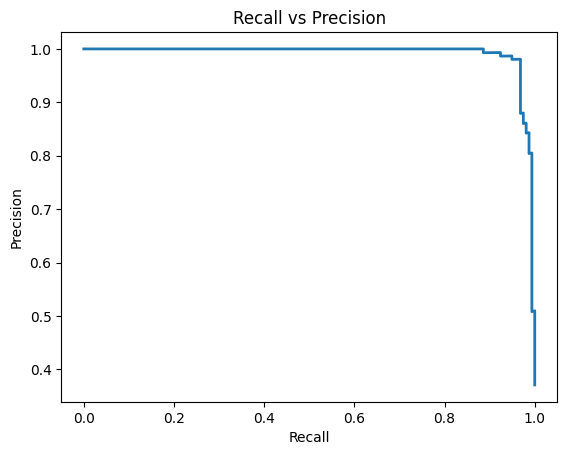

In [71]:
#here is a graph of all of the recalls vs all the precisions
plt.plot(recall, precision, linewidth=2, label="Recall vs Precision")
plt.title("Recall vs Precision")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()
#we can see that as the recall is at its highest(never misses), the precision is lowest because it is flagging everyone. But when the precision is at its highest(always right when flags) the recall is low because it is selective

In [52]:
#finidng a threshold to use when we want to catch 98% of cancers-- recall of 98% 
ok_recalls = recall[:-1] >= 0.98
highest_threshold = threshold[ok_recalls].max() #we use the highest threshold that still has 98% recall so the precision is maximized
chosen_precision = precision[:-1][ok_recalls][-1]
chosen_precision #we got a 86% precision with a 98% recall which is good for cancer. It means that we only miss a patient who truly has cancer 2% of the time but when we say they do we are 86% sure


np.float64(0.8611111111111112)

In [ ]:
#now using our threshold, lets see which scores from the cv result are going to be classified as what
y_predict = (scores >= highest_threshold).astype(int)


array([0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0,
       0, 0, 1, 0, 1, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1,

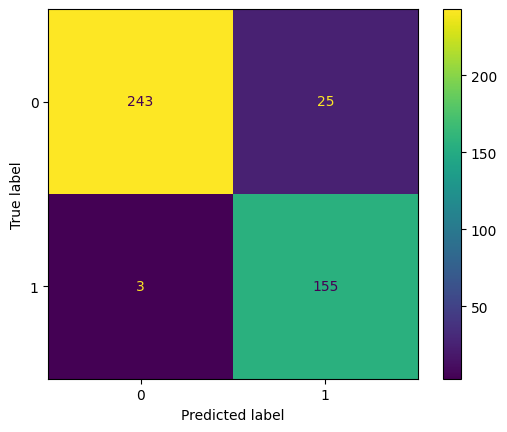

In [59]:
#now lets plug into our confusion matrix to see how it performed
cm2 = confusion_matrix(y_true=y_train,y_pred=y_predict)
cm_graph = ConfusionMatrixDisplay(cm2)
cm_graph.plot()
plt.show()

In [63]:
#now our metrics:
precision = precision_score(y_true=y_train, y_pred=y_predict)
recall = recall_score(y_true=y_train, y_pred=y_predict)
accuracy = accuracy_score(y_true=y_train, y_pred=y_predict)
precision,recall,accuracy, highest_threshold

(0.8611111111111112,
 0.9810126582278481,
 0.9342723004694836,
 np.float64(-2.1326320787971875))

Using my chosen recall of 98%, I have a threshold of -2.13. This moved my precision down to 86%, but for cancer I'm fine with that because it means we only miss 2% of positive cancer pateitns with a FN now even tho when we predict it to be positve we are only 86% sure.